# DSCI 552 Homework 7

**Name:** Hanwen Zhang  
**GitHub Username:** zhw123456789

## 1(a). Anuran Calls data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from joblib import Parallel, delayed, parallel_config
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from threadpoolctl import threadpool_limits

seed = 552
workers = 6
data = pd.read_csv(Path("../data/Frogs_MFCCs.csv"))
label_names = ["Family", "Genus", "Species"]
X = data.filter(like="MFCCs_").to_numpy()
y = data[label_names]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.70, random_state=seed, stratify=y["Species"]
)
print(f"{len(X_train):,} training rows, {len(X_test):,} test rows, {X.shape[1]} features")

5,036 training rows, 2,159 test rows, 22 features


The split is random and stratified by species. I used the MFCC columns as predictors and left out the recording identifier.

## 1(b)(i). Evaluation

Exact match is the fraction of rows with all three labels correct. Hamming distance counts the incorrect labels in a row. Hamming loss averages that count and divides by three. Hamming score is one minus the loss.

In [2]:
def hamming_metrics(actual, predicted):
    wrong = np.asarray(actual) != np.asarray(predicted)
    return {
        "Mean Hamming distance": wrong.sum(axis=1).mean(),
        "Hamming loss": wrong.mean(),
        "Hamming score": 1 - wrong.mean(),
    }


def test_metrics(actual, predicted):
    result = {"Exact match": (actual == predicted).all(axis=1).mean()}
    result.update(hamming_metrics(actual, predicted))
    result["Mean macro recall"] = np.mean([
        recall_score(actual[label], predicted[label], average="macro", zero_division=0)
        for label in label_names
    ])
    return result

## 1(b)(ii). Gaussian SVM

I used the original MFCC values. For each label, one-versus-rest SVMs use the Gaussian kernel with $\gamma=1/(2\sigma^2)$. A stratified 10-fold search selects $C$ and $\sigma$ by validation accuracy.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)


def fit_each_label(estimator, grid):
    predictions = pd.DataFrame(index=y_test.index)
    settings = []
    with parallel_config(backend="loky", inner_max_num_threads=1):
        for label in label_names:
            search = GridSearchCV(
                estimator, grid, cv=cv, scoring="accuracy",
                n_jobs=workers, error_score="raise",
            )
            search.fit(X_train, y_train[label])
            predictions[label] = search.predict(X_test)
            settings.append({"Label": label, **search.best_params_, "CV accuracy": search.best_score_})
    return predictions, pd.DataFrame(settings).set_index("Label")


widths = np.array([0.15, 0.3, 0.6, 1.2, 2.4])
rbf_grid = {
    "estimator__C": [0.1, 1, 10, 100, 1000],
    "estimator__gamma": 1 / (2 * widths**2),
}
rbf_model = OneVsRestClassifier(SVC(kernel="rbf", cache_size=128))
rbf_pred, rbf_settings = fit_each_label(rbf_model, rbf_grid)
rbf_settings = rbf_settings.rename(columns={"estimator__C": "C", "estimator__gamma": "gamma"})
rbf_settings["sigma"] = (2 * rbf_settings["gamma"]) ** -0.5
display(rbf_settings[["C", "sigma", "gamma", "CV accuracy"]].round(4))

,C,sigma,gamma,CV accuracy
Label,,,,
Family,10,0.6,1.3889,0.9936
Genus,10,0.6,1.3889,0.9905
Species,10,0.6,1.3889,0.9909


## 1(b)(iii). L1 linear SVM

The scaler is fitted separately in each training fold. LinearSVC uses one-versus-rest classification and an L1 penalty.

In [4]:
linear_svm = LinearSVC(penalty="l1", dual=False, max_iter=20000, random_state=seed)
linear_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100]}
linear_model = Pipeline([("scale", StandardScaler()), ("svm", linear_svm)])

linear_pred, linear_settings = fit_each_label(linear_model, linear_grid)
display(linear_settings.rename(columns={"svm__C": "C"}).round(4))

,C,CV accuracy
Label,,
Family,1,0.9382
Genus,10,0.9523
Species,1,0.9575


## 1(b)(iv). L1 linear SVM with SMOTE

SMOTE balances each target separately using the scaled training fold. The validation folds and test set keep their original class counts.

In [5]:
smote_model = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=seed)),
    ("svm", linear_svm),
])
smote_pred, smote_settings = fit_each_label(smote_model, linear_grid)
display(smote_settings.rename(columns={"svm__C": "C"}).round(4))

test_results = pd.DataFrame({
    "Gaussian SVM": test_metrics(y_test, rbf_pred),
    "L1 linear SVM": test_metrics(y_test, linear_pred),
    "L1 linear SVM + SMOTE": test_metrics(y_test, smote_pred),
}).T
display(test_results.round(4))

,C,CV accuracy
Label,,
Family,10.0,0.9293
Genus,10.0,0.9251
Species,0.1,0.9549


,Exact match,Mean Hamming distance,Hamming loss,Hamming score,Mean macro recall
Gaussian SVM,0.9870,0.0278,0.0093,0.9907,0.9525
L1 linear SVM,0.9166,0.1528,0.0509,0.9491,0.8049
L1 linear SVM + SMOTE,0.8657,0.2094,0.0698,0.9302,0.9036


The Gaussian SVM gave the best exact match (98.70%) and the lowest Hamming loss (0.93%). SMOTE raised mean macro recall from 80.49% to 90.36%, while exact match fell from 91.66% to 86.57%. Mean macro recall gives equal weight to the classes within each label.

The SMOTE grid search reported a convergence warning. I checked the three selected models separately, and all converged on the full training set.

## 2(a). Selecting the number of clusters

Each trial runs K-means on all 7,195 rows with a different seed and selects the highest Calinski-Harabasz score. The score needs at least two clusters, so the scored range is 2 through 50. I used three initializations for each candidate.

## 2(b). Majority labels

I took the mode of each label column within each cluster. For a tie I used the first label in alphabetical order.

## 2(c). Hamming metrics over 50 trials

In [6]:
def cluster_trial(trial_seed):
    best_score = -np.inf
    with threadpool_limits(limits=1):
        for k in range(2, 51):
            cluster = KMeans(n_clusters=k, n_init=3, random_state=trial_seed).fit_predict(X)
            score = calinski_harabasz_score(X, cluster)
            if score > best_score:
                best_k, best_cluster, best_score = k, cluster, score

    groups = y.assign(Cluster=best_cluster).groupby("Cluster")
    majority = groups[label_names].agg(lambda labels: labels.mode().iloc[0])
    predicted = majority.loc[best_cluster].to_numpy()
    return best_k, majority, hamming_metrics(y, predicted)


with parallel_config(backend="loky", inner_max_num_threads=1):
    trials = Parallel(n_jobs=workers)(
        delayed(cluster_trial)(seed + trial) for trial in range(50)
    )

chosen_k = pd.Series([k for k, _, _ in trials], name="k")
cluster_results = pd.DataFrame([scores for _, _, scores in trials])
print(f"Selected k counts: {chosen_k.value_counts().sort_index().to_dict()}")
print("Majority labels in the first trial")
display(trials[0][1])
display(cluster_results.agg(["mean", "std"]).round(6))

Selected k counts: {2: 50}
Majority labels in the first trial


,Family,Genus,Species
Cluster,,,
0,Hylidae,Hypsiboas,HypsiboasCordobae
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


,Mean Hamming distance,Hamming loss,Hamming score
mean,0.895622,0.298541,0.701459
std,0.000000,0.000000,0.000000


All 50 trials selected $k=2$ and produced the same Hamming statistics. The mean distance was 0.896 incorrect labels per observation.

## 3. ISLR 12.6.2

**(a) Complete linkage.** Observations 1 and 2 merge at 0.30. Observations 3 and 4 merge at 0.45. The two clusters merge at 0.80, the largest distance between the clusters.

**(b) Single linkage.** Observations 1 and 2 merge at 0.30. Observation 3 joins them at 0.40 through observation 1. Observation 4 joins at 0.45 through observation 3.

**(c)** A cut at 0.60 in (a) gives {1, 2} and {3, 4}.

**(d)** A cut at 0.425 in (b) gives {1, 2, 3} and {4}.

**(e)** The order 2, 1, 4, 3 swaps the branches within both pairs and keeps all three merge heights.

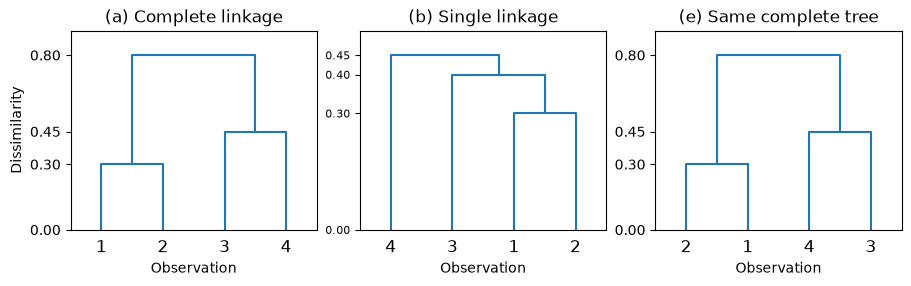

In [7]:
distances = np.array([
    [0, 0.30, 0.40, 0.70],
    [0.30, 0, 0.50, 0.80],
    [0.40, 0.50, 0, 0.45],
    [0.70, 0.80, 0.45, 0],
])
complete = linkage(squareform(distances), method="complete")
single = linkage(squareform(distances), method="single")
reordered = complete.copy()
reordered[:2, :2] = complete[:2, 1::-1]

fig, axes = plt.subplots(1, 3, figsize=(9, 2.75), layout="constrained")
for ax, tree, title, heights in zip(
    axes, [complete, single, reordered],
    ["(a) Complete linkage", "(b) Single linkage", "(e) Same complete tree"],
    [[0, 0.30, 0.45, 0.80], [0, 0.30, 0.40, 0.45], [0, 0.30, 0.45, 0.80]],
):
    dendrogram(tree, labels=["1", "2", "3", "4"], ax=ax, color_threshold=0)
    ax.set(title=title, xlabel="Observation", yticks=heights, ylim=(0, heights[-1] * 1.14))
    if title.startswith("(b)"):
        ax.tick_params(axis="y", labelsize=8)
axes[0].set_ylabel("Dissimilarity")
plt.show()

## Sources

- Colonna, Juan, et al. [Anuran Calls (MFCCs)](https://doi.org/10.24432/C5CC9H). UCI Machine Learning Repository, 2015. CC BY 4.0.
- [Scikit-learn classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics), [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), and [Calinski-Harabasz score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html).
- [Imbalanced-learn guidance on resampling and cross-validation](https://imbalanced-learn.org/stable/common_pitfalls.html#data-leakage).
- James, Gareth, et al. *An Introduction to Statistical Learning*, second edition, exercise 12.6.2.